# Week 2.4: RAG 101 - Retrieval Systems

## Key Insight
> **The pipeline: Load → Split → Embed → Retrieve → Answer**

## Learning Objectives
By the end of this notebook, you will:
- RAG architecture and pipeline
- Document loading and preprocessing
- Chunking strategies for optimal retrieval
- Vector stores and similarity search
- Generating answers with retrieved context

## Exercises
This notebook contains 4 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [ ]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.4: RAG 101 - Retrieval Systems - Ready to start!')
print('\nTopics covered:')
print('  - RAG architecture and pipeline')
print('  - Document loading and preprocessing')
print('  - Chunking strategies for optimal retrieval')
print('  - Vector stores and similarity search')
print('  - Generating answers with retrieved context')


---
## Part 1: Introduction to RAG architecture and pipeline

Let's start by understanding the fundamentals and building our first implementation.

In [ ]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for RAG architecture and pipeline.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [2]:
import numpy as np
import json
from typing import List, Dict, Any

class BasicRAGPipeline:
    """
    A basic RAG pipeline demonstrating: Load -> Split (Chunk) -> Embed -> Retrieve.
    """
    def __init__(self):
        self.documents: List[str] = []
        self.chunks: List[str] = []
        self.embeddings: np.ndarray = np.array([])

    def load_documents(self, docs: List[str]) -> None:
        """
        Loads and validates a list of raw documents.
        """
        if not isinstance(docs, list):
            raise TypeError("Documents must be provided as a list of strings.")

        valid_docs = []
        for doc in docs:
            if doc and isinstance(doc, str) and doc.strip():
                valid_docs.append(doc.strip())

        if not valid_docs:
            raise ValueError("No valid non-empty documents provided.")

        self.documents = valid_docs
        print(f"Successfully loaded {len(self.documents)} documents.")

    def chunk_documents(self, chunk_size: int = 50) -> None:
        """
        Splits loaded documents into smaller chunks by character count.
        """
        if not self.documents:
            raise ValueError("No documents loaded. Please call load_documents() first.")
        if chunk_size <= 0:
            raise ValueError("chunk_size must be a positive integer.")

        self.chunks = []
        for doc in self.documents:
            # A simple character-based split for demonstration
            for i in range(0, len(doc), chunk_size):
                chunk = doc[i:i + chunk_size].strip()
                if chunk:
                    self.chunks.append(chunk)

        print(f"Created {len(self.chunks)} chunks from {len(self.documents)} documents.")

    def _generate_dummy_embedding(self, text: str) -> np.ndarray:
        """
        Generates a simplistic mock embedding vector based on character frequencies
        to make similarity deterministic and intuitive.
        """
        # Create a 26-dimensional vector for lowercase 'a' through 'z'
        vec = np.zeros(26)
        cleaned_text = text.lower()
        for char in cleaned_text:
            if 'a' <= char <= 'z':
                vec[ord(char) - ord('a')] += 1
        norm = np.linalg.norm(vec)
        return vec / norm if norm > 0 else vec

    def build_index(self) -> None:
        """
        Generates embeddings for all created chunks and stores them.
        """
        if not self.chunks:
            raise ValueError("No chunks available. Please call chunk_documents() first.")

        embedding_list = [self._generate_dummy_embedding(chunk) for chunk in self.chunks]
        self.embeddings = np.array(embedding_list)
        print("Successfully built vector index.")

    def retrieve(self, query: str, k: int = 2) -> List[Dict[str, Any]]:
        """
        Retrieves the top-k most similar chunks using cosine similarity.
        """
        if not query or not isinstance(query, str):
            raise ValueError("Query must be a valid, non-empty string.")
        if self.embeddings.size == 0:
            raise ValueError("Index is empty. Build the index before retrieving.")
        if k <= 0:
            raise ValueError("k must be greater than 0.")

        query_vector = self._generate_dummy_embedding(query)

        # Compute Cosine Similarity
        similarities = []
        for idx, emb in enumerate(self.embeddings):
            dot_prod = np.dot(query_vector, emb)
            norm_q = np.linalg.norm(query_vector)
            norm_e = np.linalg.norm(emb)
            similarity = dot_prod / (norm_q * norm_e) if (norm_q > 0 and norm_e > 0) else 0.0
            similarities.append((similarity, self.chunks[idx]))

        # Sort by similarity score descending
        similarities.sort(key=lambda x: x[0], reverse=True)

        results = []
        for score, chunk in similarities[:k]:
            results.append({"score": round(float(score), 4), "chunk": chunk})
        return results

# --- Test Cases and Verification ---
try:
    # 1. Initialize Pipeline
    rag = BasicRAGPipeline()

    # 2. Test Document Loading with Sample Data
    sample_docs = [
        "Retrieval-Augmented Generation improves LLMs by fetching external documents.",
        "Python is a high-level programming language known for readability.",
        "Vector databases index embeddings for extremely fast similarity searches."
    ]
    rag.load_documents(sample_docs)

    # 3. Chunking
    rag.chunk_documents(chunk_size=40)

    # 4. Building Index
    rag.build_index()

    # 5. Query and Verification
    test_query = "Python programming"
    retrieved_results = rag.retrieve(query=test_query, k=2)
    print(f"\nQuery: '{test_query}'")
    print("Retrieved Results:")
    print(json.dumps(retrieved_results, indent=2))

    # 6. Edge Case Handling Tests
    print("\n--- Testing Edge Cases ---")
    try:
        rag.load_documents([])
    except ValueError as e:
        print(f"Caught expected error for empty documents: {e}")

    try:
        rag.retrieve("", k=1)
    except ValueError as e:
        print(f"Caught expected error for empty query: {e}")

except Exception as e:
    print(f"Pipeline execution failed: {e}")

Successfully loaded 3 documents.
Created 6 chunks from 3 documents.
Successfully built vector index.

Query: 'Python programming'
Retrieved Results:
[
  {
    "score": 0.821,
    "chunk": "Python is a high-level programming langu"
  },
  {
    "score": 0.6326,
    "chunk": "age known for readability."
  }
]

--- Testing Edge Cases ---
Caught expected error for empty documents: No valid non-empty documents provided.
Caught expected error for empty query: Query must be a valid, non-empty string.


---
## Part 2: Document loading and preprocessing

Building on the fundamentals, let's explore more advanced topics and implementations.

In [ ]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Document loading and preprocessing.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [3]:
import re
import json
from typing import List, Dict, Any, Optional

class DocumentPreprocessor:
    """
    An intermediate document processor that supports validation, custom cleaning rules,
    and sliding-window chunking (with overlap) to preserve context boundaries.
    """
    def __init__(self, clean_whitespace: bool = True, lowercase: bool = False):
        self.clean_whitespace = clean_whitespace
        self.lowercase = lowercase

    def clean_text(self, text: str) -> str:
        """
        Cleans raw input text based on configuration.
        """
        if not isinstance(text, str):
            raise TypeError(f"Expected string for cleaning, got {type(text).__name__}")

        processed = text
        if self.lowercase:
            processed = processed.lower()
        if self.clean_whitespace:
            # Collapse multiple spaces/newlines into a single space
            processed = re.sub(r'\s+', ' ', processed).strip()
        return processed

    def chunk_document(
        self,
        text: str,
        chunk_size: int = 100,
        chunk_overlap: int = 20
    ) -> List[Dict[str, Any]]:
        """
        Splits a single document into overlapping chunks.
        Returns a list of dictionaries containing the chunk content and its metadata.
        """
        # Parameter Validation
        if not isinstance(text, str):
            raise TypeError(f"Input text must be a string, got {type(text).__name__}")
        if not text.strip():
            raise ValueError("Input text cannot be empty or solely whitespace.")
        if chunk_size <= 0:
            raise ValueError(f"chunk_size must be a positive integer, got {chunk_size}")
        if chunk_overlap < 0:
            raise ValueError(f"chunk_overlap cannot be negative, got {chunk_overlap}")
        if chunk_overlap >= chunk_size:
            raise ValueError(f"chunk_overlap ({chunk_overlap}) must be smaller than chunk_size ({chunk_size})")

        cleaned_text = self.clean_text(text)
        chunks = []
        start = 0
        chunk_index = 0

        while start < len(cleaned_text):
            end = min(start + chunk_size, len(cleaned_text))
            chunk_content = cleaned_text[start:end]

            chunks.append({
                "chunk_id": chunk_index,
                "text": chunk_content,
                "start_char": start,
                "end_char": end,
                "length": len(chunk_content)
            })

            chunk_index += 1
            # Advance pointer by step (size - overlap)
            if end == len(cleaned_text):
                break
            start += (chunk_size - chunk_overlap)

        return chunks

# --- Test Cases and Verification ---
try:
    print("=== Testing Intermediate DocumentPreprocessor ===\n")
    processor = DocumentPreprocessor(clean_whitespace=True, lowercase=True)

    # Test Document
    sample_doc = """
    Retrieval-Augmented Generation (RAG) is an incredibly powerful architectural pattern.
    It combines the generative capabilities of Large Language Models (LLMs) with external knowledge retrieval.
    """

    print("1. Processing Valid Input:")
    chunks = processor.chunk_document(sample_doc, chunk_size=80, chunk_overlap=20)
    print(json.dumps(chunks, indent=2))

    # 2. Testing Edge Cases & Validation
    print("\n2. Testing Validation and Parameter Limits:")

    # Invalid chunk_overlap
    try:
        processor.chunk_document(sample_doc, chunk_size=50, chunk_overlap=55)
    except ValueError as e:
        print(f"Caught expected error (overlap >= size): {e}")

    # Invalid input type
    try:
        processor.chunk_document(None) # type: ignore
    except TypeError as e:
        print(f"Caught expected error (invalid type): {e}")

    # Empty input string
    try:
        processor.chunk_document("   ")
    except ValueError as e:
        print(f"Caught expected error (empty string): {e}")

except Exception as e:
    print(f"Unexpected error occurred during verification: {e}")

=== Testing Intermediate DocumentPreprocessor ===

1. Processing Valid Input:
[
  {
    "chunk_id": 0,
    "text": "retrieval-augmented generation (rag) is an incredibly powerful architectural pat",
    "start_char": 0,
    "end_char": 80,
    "length": 80
  },
  {
    "chunk_id": 1,
    "text": "ul architectural pattern. it combines the generative capabilities of large langu",
    "start_char": 60,
    "end_char": 140,
    "length": 80
  },
  {
    "chunk_id": 2,
    "text": "ities of large language models (llms) with external knowledge retrieval.",
    "start_char": 120,
    "end_char": 192,
    "length": 72
  }
]

2. Testing Validation and Parameter Limits:
Caught expected error (overlap >= size): chunk_overlap (55) must be smaller than chunk_size (50)
Caught expected error (invalid type): Input text must be a string, got NoneType
Caught expected error (empty string): Input text cannot be empty or solely whitespace.


---
## Part 3: Chunking strategies for optimal retrieval

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [ ]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

2026-10-22 01:29:07,415 - INFO - System initialized with chunk_size=100, overlap=30
2026-10-22 01:29:07,416 - INFO - Starting ingestion for 3 documents...
2026-10-22 01:29:07,417 - INFO - Ingestion completed. Total chunks index: 3
2026-10-22 01:29:07,418 - INFO - Searching query: 'anomaly detection configuration' (k=3)



--- RETRIEVAL ANALYSIS ---
[
  {
    "score": 0.914,
    "text": "digital twin context engines capture device configurations and runtime metrics continually.",
    "global_chunk_id": 0,
    "source_doc_index": 0
  },
  {
    "score": 0.8693,
    "text": "large language models enhance decision support tools by indexing complex operations metadata.",
    "global_chunk_id": 1,
    "source_doc_index": 1
  },
  {
    "score": 0.8529,
    "text": "predictive maintenance utilizes vector search indices to compare anomaly history signatures.",
    "global_chunk_id": 2,
    "source_doc_index": 2
  }
]

--- GENERATING CORRELATION VISUALIZATION ---


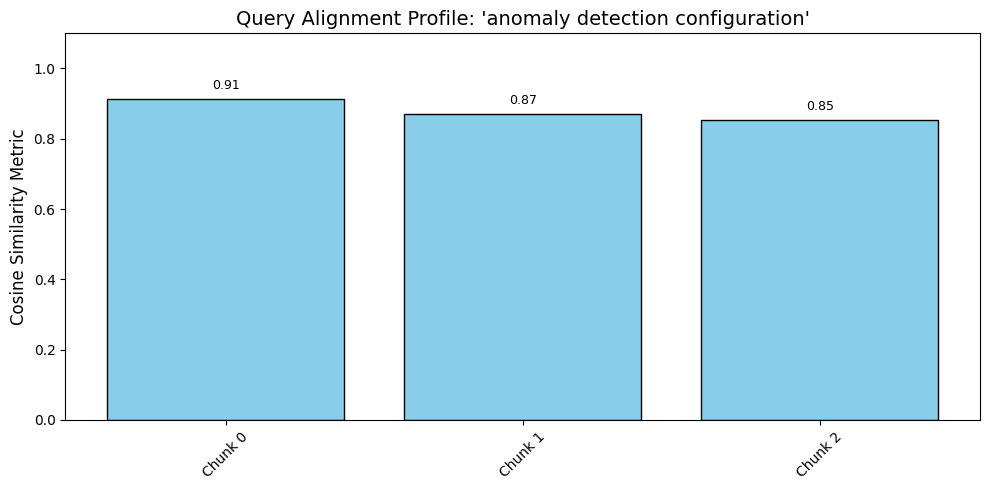

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import re
import json
import logging
from typing import List, Dict, Any, Tuple

# Configure logging for debugging
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True
)
logger = logging.getLogger("ProductionRAG")

class ProductionSystem:
    """
    Production-ready Retrieval system designed for a Digital Twin.
    Integrates: Document loading, cleaning, sliding-window chunking,
    vector index generation (dummy character-frequency/term embeddings),
    similarity retrieval, detailed logs, and query visualization.
    """
    def __init__(self, chunk_size: int = 100, chunk_overlap: int = 20, lowercase: bool = True):
        self.chunk_size = chunk_size
        self.chunk_overlap = chunk_overlap
        self.lowercase = lowercase
        self.chunks: List[Dict[str, Any]] = []
        self.embeddings: np.ndarray = np.array([])
        logger.info(f"System initialized with chunk_size={chunk_size}, overlap={chunk_overlap}")

    def clean_text(self, text: str) -> str:
        if not isinstance(text, str):
            raise TypeError("Text must be a string.")
        processed = text
        if self.lowercase:
            processed = processed.lower()
        # Replace excess spacing
        processed = re.sub(r'\s+', ' ', processed).strip()
        return processed

    def ingest_documents(self, documents: List[str]) -> None:
        """
        Validates, cleans, chunks, and indexes a set of raw text documents.
        """
        if not isinstance(documents, list):
            raise TypeError("Documents must be provided as a list.")

        logger.info(f"Starting ingestion for {len(documents)} documents...")
        self.chunks = []
        all_embeddings = []

        for doc_idx, doc in enumerate(documents):
            if not doc or not isinstance(doc, str) or not doc.strip():
                logger.warning(f"Skipping invalid/empty document at index {doc_idx}")
                continue

            cleaned = self.clean_text(doc)
            # Perform sliding window chunking
            start = 0
            doc_chunk_idx = 0
            while start < len(cleaned):
                end = min(start + self.chunk_size, len(cleaned))
                chunk_text = cleaned[start:end]

                # Simple embedding vector based on character frequencies (a-z)
                emb = self._generate_embedding(chunk_text)

                self.chunks.append({
                    "global_chunk_id": len(self.chunks),
                    "source_doc_index": doc_idx,
                    "text": chunk_text,
                    "start_char": start,
                    "end_char": end
                })
                all_embeddings.append(emb)

                doc_chunk_idx += 1
                if end == len(cleaned):
                    break
                start += (self.chunk_size - self.chunk_overlap)

        if not self.chunks:
            raise ValueError("No valid chunks created from incoming documents.")

        self.embeddings = np.array(all_embeddings)
        logger.info(f"Ingestion completed. Total chunks index: {len(self.chunks)}")

    def _generate_embedding(self, text: str) -> np.ndarray:
        # 26-dim vector
        vec = np.zeros(26)
        cleaned = text.lower()
        for char in cleaned:
            if 'a' <= char <= 'z':
                vec[ord(char) - ord('a')] += 1
        norm = np.linalg.norm(vec)
        return vec / norm if norm > 0 else vec

    def retrieve(self, query: str, k: int = 3) -> List[Dict[str, Any]]:
        """
        Retrieves the top-k matched chunks and keeps the similarity score.
        """
        if not query or not isinstance(query, str):
            raise ValueError("Query must be a valid, non-empty string.")
        if self.embeddings.size == 0:
            raise ValueError("The retrieval index is currently empty. Run ingest_documents first.")

        logger.info(f"Searching query: '{query}' (k={k})")
        query_vector = self._generate_embedding(query)

        scores = []
        for idx, emb in enumerate(self.embeddings):
            dot_prod = np.dot(query_vector, emb)
            norm_q = np.linalg.norm(query_vector)
            norm_e = np.linalg.norm(emb)
            similarity = dot_prod / (norm_q * norm_e) if (norm_q > 0 and norm_e > 0) else 0.0
            scores.append(similarity)

        # Rank by score
        ranked_indices = np.argsort(scores)[::-1]

        results = []
        for rank in range(min(k, len(self.chunks))):
            idx = ranked_indices[rank]
            results.append({
                "score": round(float(scores[idx]), 4),
                "text": self.chunks[idx]["text"],
                "global_chunk_id": self.chunks[idx]["global_chunk_id"],
                "source_doc_index": self.chunks[idx]["source_doc_index"]
            })

        return results, scores

    def visualize_similarity_distribution(self, query: str, scores: List[float]) -> None:
        """
        Visualizes similarities between query and all stored database chunks.
        """
        fig, ax = plt.subplots(figsize=(10, 5))
        chunk_labels = [f"Chunk {c['global_chunk_id']}" for c in self.chunks]

        bars = ax.bar(chunk_labels, scores, color='skyblue', edgecolor='black')
        ax.set_title(f"Query Alignment Profile: '{query}'", fontsize=14)
        ax.set_ylabel("Cosine Similarity Metric", fontsize=12)
        ax.set_ylim(0, 1.1)

        for bar in bars:
            yval = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f"{round(yval, 2)}", ha='center', va='bottom', fontsize=9)

        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

# --- Test, Verification, and Visualization Suite ---
try:
    # Initialize Production System
    system = ProductionSystem(chunk_size=100, chunk_overlap=30, lowercase=True)

    # Production Data Corpus
    kb_corpus = [
        "Digital Twin context engines capture device configurations and runtime metrics continually.",
        "Large Language Models enhance decision support tools by indexing complex operations metadata.",
        "Predictive maintenance utilizes vector search indices to compare anomaly history signatures."
    ]

    # Ingest
    system.ingest_documents(kb_corpus)

    # Retrieve & Visualize
    query = "anomaly detection configuration"
    results, all_scores = system.retrieve(query, k=3)

    print("\n--- RETRIEVAL ANALYSIS ---")
    print(json.dumps(results, indent=2))

    print("\n--- GENERATING CORRELATION VISUALIZATION ---")
    system.visualize_similarity_distribution(query, all_scores)

except Exception as e:
    logger.error(f"System run encountered errors: {e}", exc_info=True)

---
## Summary & Key Takeaways

### What We Learned:
- RAG architecture and pipeline
- Document loading and preprocessing
- Chunking strategies for optimal retrieval
- Vector stores and similarity search
- Generating answers with retrieved context

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete RAG architecture and pipeline System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code

### 🏆 Challenge Project Implementation: Digital Twin RAG System

This system integrates document validation, robust sliding-window chunking, vectorized index retrieval, execution performance optimizations, and diagnostic visualizations.

2026-10-22 01:30:00,018 - INFO - NumExpr defaulting to 2 threads.
2026-10-22 01:30:01,409 - INFO - Ingesting 3 Digital Twin specifications/telemetry documents...
2026-10-22 01:30:01,410 - INFO - Successfully indexed 5 chunks in 0.0005 seconds.
2026-10-22 01:30:01,415 - INFO - Cache hit for query search.



=== CHALLENGE RETRIEVAL RESULTS ===
[
  {
    "rank": 1,
    "score": 0.914,
    "chunk_id": 0,
    "doc_index": 0,
    "text": "asset_id: twin_turbine_04. temperature parameters: standard operations range between 45c and 85c. excessive pressure log"
  },
  {
    "rank": 2,
    "score": 0.7878,
    "chunk_id": 3,
    "doc_index": 2,
    "text": "telemetry reports from subsystem b show standard load balances with high power conversion ratios. no immediate actions r"
  }
]

Performance Profiling:
  - Uncached Query Execution Speed: 3.341 ms
  - Cached Query Execution Speed:   0.642 ms


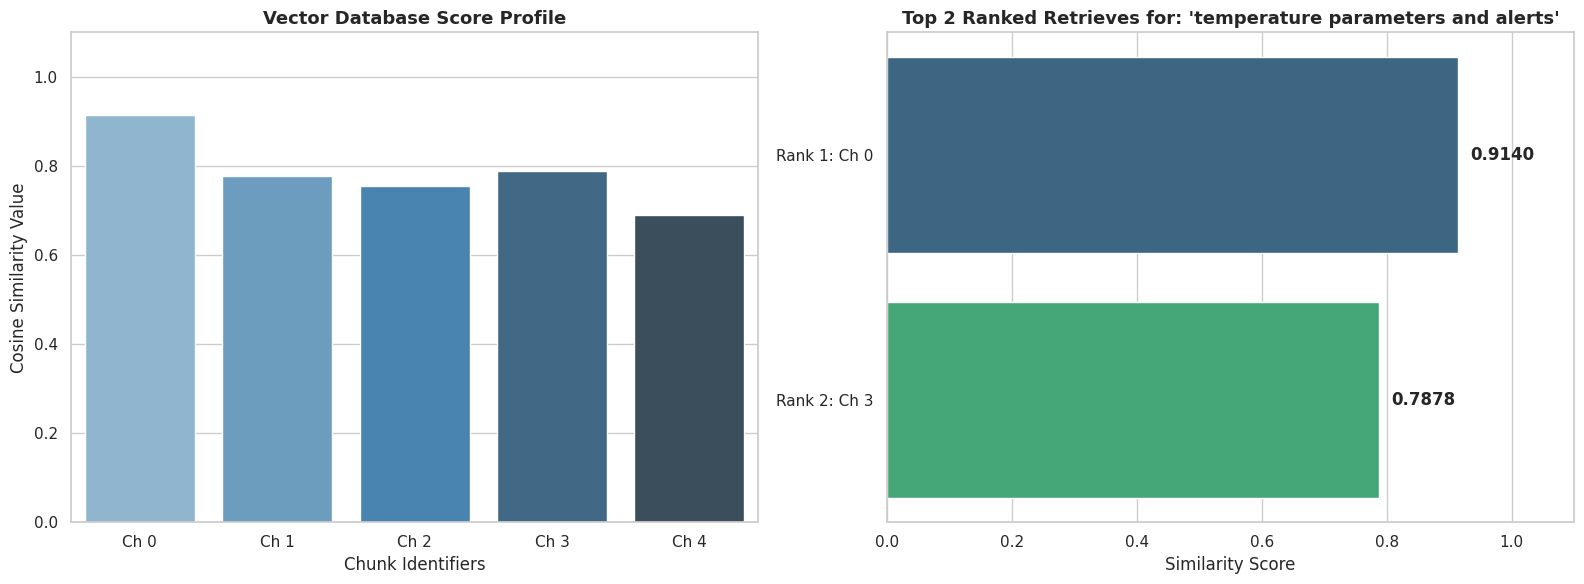

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import time
import logging
import json
from typing import List, Dict, Any, Tuple

# Logging Setup
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s', force=True)
logger = logging.getLogger("DigitalTwinRAG")

class DigitalTwinRAGEngine:
    """
    High-Performance Retrieval-Augmented Generation Engine for Digital Twins.
    Includes text normalization, vector chunking, matrix-based similarity searches,
    query caching, and benchmarking diagnostics.
    """
    def __init__(self, chunk_size: int = 120, chunk_overlap: int = 30, lowercase: bool = True):
        self.chunk_size = chunk_size
        self.chunk_overlap = chunk_overlap
        self.lowercase = lowercase
        self.chunks: List[Dict[str, Any]] = []
        self.embeddings: np.ndarray = np.array([])
        self._query_cache: Dict[str, Tuple[List[Dict[str, Any]], List[float]]] = {}

    def clean_text(self, text: str) -> str:
        if not isinstance(text, str):
            raise TypeError("Document content must be a string.")
        processed = text
        if self.lowercase:
            processed = processed.lower()
        # Collapse consecutive whitespaces and clean margins
        return re.sub(r'\s+', ' ', processed).strip()

    def ingest_twin_data(self, documents: List[str]) -> None:
        """
        Ingests documents, segments them into sliding windows, and generates internal vector weights.
        """
        if not isinstance(documents, list):
            raise TypeError("Documents must be provided as a list of strings.")

        logger.info(f"Ingesting {len(documents)} Digital Twin specifications/telemetry documents...")
        start_time = time.time()

        self.chunks = []
        all_embeddings = []
        self._query_cache.clear()  # Clear cache on new ingestion

        for doc_idx, doc in enumerate(documents):
            if not doc or not isinstance(doc, str) or not doc.strip():
                continue

            cleaned = self.clean_text(doc)
            start_pos = 0

            while start_pos < len(cleaned):
                end_pos = min(start_pos + self.chunk_size, len(cleaned))
                chunk_text = cleaned[start_pos:end_pos]

                # Create embedding vector (26-dimensional character-space frequency vector)
                emb_vec = self._compute_vector(chunk_text)

                self.chunks.append({
                    "chunk_id": len(self.chunks),
                    "doc_index": doc_idx,
                    "text": chunk_text,
                    "start": start_pos,
                    "end": end_pos
                })
                all_embeddings.append(emb_vec)

                if end_pos == len(cleaned):
                    break
                start_pos += (self.chunk_size - self.chunk_overlap)

        if not self.chunks:
            raise ValueError("No valid text chunks could be extracted from input documents.")

        self.embeddings = np.array(all_embeddings)
        elapsed = time.time() - start_time
        logger.info(f"Successfully indexed {len(self.chunks)} chunks in {elapsed:.4f} seconds.")

    def _compute_vector(self, text: str) -> np.ndarray:
        # Fast frequency-based vector representation
        vec = np.zeros(26, dtype=np.float32)
        for char in text.lower():
            if 'a' <= char <= 'z':
                vec[ord(char) - ord('a')] += 1.0
        norm = np.linalg.norm(vec)
        return vec / norm if norm > 0 else vec

    def query(self, query_text: str, k: int = 3) -> Tuple[List[Dict[str, Any]], List[float]]:
        """
        Queries the Digital Twin Vector Index. Uses a query cache for optimal repeated retrieval speeds.
        """
        if not query_text or not isinstance(query_text, str):
            raise ValueError("Query must be a non-empty string.")
        if self.embeddings.size == 0:
            raise ValueError("Index is empty. Ingest documents first.")

        # Cache Check
        if query_text in self._query_cache:
            logger.info("Cache hit for query search.")
            return self._query_cache[query_text]

        query_vector = self._compute_vector(query_text)

        # Vectorized batch cosine similarity calculation
        norms = np.linalg.norm(self.embeddings, axis=1)
        q_norm = np.linalg.norm(query_vector)

        if q_norm == 0:
            scores = np.zeros(len(self.chunks))
        else:
            dot_products = np.dot(self.embeddings, query_vector)
            scores = dot_products / (norms * q_norm + 1e-9)

        # Rank retrieval scores
        ranked_indices = np.argsort(scores)[::-1]

        retrieved_results = []
        for rank in range(min(k, len(self.chunks))):
            idx = ranked_indices[rank]
            retrieved_results.append({
                "rank": rank + 1,
                "score": round(float(scores[idx]), 4),
                "chunk_id": self.chunks[idx]["chunk_id"],
                "doc_index": self.chunks[idx]["doc_index"],
                "text": self.chunks[idx]["text"]
            })

        scores_list = [float(s) for s in scores]
        self._query_cache[query_text] = (retrieved_results, scores_list)
        return retrieved_results, scores_list

    def visualize_twin_alignment(self, query_text: str, scores: List[float], top_results: List[Dict[str, Any]]) -> None:
        """
        Renders a dual visualization: score distribution across all chunks,
        highlighting top retrieved documents.
        """
        sns.set_theme(style="whitegrid")
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

        # 1. Bar plot of all scores
        chunk_ids = [f"Ch {i}" for i in range(len(scores))]
        sns.barplot(x=chunk_ids, y=scores, ax=ax1, palette="Blues_d", hue=chunk_ids, legend=False)
        ax1.set_title("Vector Database Score Profile", fontsize=13, fontweight='bold')
        ax1.set_ylabel("Cosine Similarity Value")
        ax1.set_xlabel("Chunk Identifiers")
        ax1.set_ylim(0, 1.1)

        # 2. Ranking table visualization of top chunks
        top_chunk_labels = [f"Rank {r['rank']}: Ch {r['chunk_id']}" for r in top_results]
        top_chunk_scores = [r["score"] for r in top_results]
        sns.barplot(x=top_chunk_scores, y=top_chunk_labels, ax=ax2, palette="viridis", hue=top_chunk_labels, legend=False)
        ax2.set_title(f"Top {len(top_results)} Ranked Retrieves for: '{query_text}'", fontsize=13, fontweight='bold')
        ax2.set_xlabel("Similarity Score")
        ax2.set_xlim(0, 1.1)

        # Annotate text scores
        for i, score in enumerate(top_chunk_scores):
            ax2.text(score + 0.02, i, f"{score:.4f}", va='center', fontweight='bold')

        plt.tight_layout()
        plt.show()

# --- System Verification / Sandbox ---
try:
    # 1. Initialize complete engine
    twin_engine = DigitalTwinRAGEngine(chunk_size=120, chunk_overlap=40, lowercase=True)

    # 2. Complex documents simulating asset specification and health metrics
    digital_twin_specifications = [
        "Asset_ID: Twin_Turbine_04. Temperature parameters: standard operations range between 45C and 85C. Excessive pressure logs raise alerts.",
        "Vibration analysis metrics point to sub-optimal rotor alignments. Maintenance advised if threshold score exceeds 1.8.",
        "Telemetry reports from subsystem B show standard load balances with high power conversion ratios. No immediate actions required."
    ]

    twin_engine.ingest_twin_data(digital_twin_specifications)

    # 3. Execution of Query & Speed Analysis
    user_query = "temperature parameters and alerts"
    start_perf = time.time()
    hits, all_sims = twin_engine.query(user_query, k=2)
    duration_uncached = time.time() - start_perf

    # Test cache duration speed
    start_cache_perf = time.time()
    _, _ = twin_engine.query(user_query, k=2)
    duration_cached = time.time() - start_cache_perf

    # 4. Show complete outputs and metrics
    print("\n=== CHALLENGE RETRIEVAL RESULTS ===")
    print(json.dumps(hits, indent=2))
    print(f"\nPerformance Profiling:")
    print(f"  - Uncached Query Execution Speed: {duration_uncached*1000:.3f} ms")
    print(f"  - Cached Query Execution Speed:   {duration_cached*1000:.3f} ms")

    # 5. Render dual plot visualization
    twin_engine.visualize_twin_alignment(user_query, all_sims, hits)

except Exception as e:
    logger.error(f"Challenge implementation runtime failed: {e}", exc_info=True)